# Walkthrough 1: from database to graph to mini-batch (Base-RelBench)

Companion to [`plans/00-baseline.md`](../plans/00-baseline.md) (§3 Dataset, §4 Sampling).
Each step runs one piece of the pipeline and prints what it produced.

| Step | What you see | Plan § |
|---|---|---|
| 1 | The 9 tables of `rel-f1` | 3 |
| 2 | The schema drawn as a graph | 3 |
| 3 | A task's training table (`driver-top3`) | 3 |
| 4 | Column types (stypes) | 3, 5.1 |
| 5 | The database as a PyG `HeteroData` graph | 3 |
| 6 | One driver followed through the graph | 3 |
| 7 | Seeds: training rows → `(node, time)` pairs | 4 |
| 8 | One sampled mini-batch, field by field | 4 |
| 9 | Check: no future rows are sampled | 4 |
| 10 | Picture of one seed's subgraph | 4 |
| 11 | Mini-batch size at the real settings | 4 |

**Run it:** `source .venv/bin/activate && jupyter nbconvert --execute --to notebook --inplace walkthroughs/01_data_graph_sampling.ipynb`,
or open it in Jupyter/VS Code. Text columns are skipped here (`text_embedder='none'`) to
avoid the 480 MB GloVe download; Part 2 explains the text encoder.

In [1]:
import os, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'walkthroughs' else Path.cwd()
os.environ.setdefault('HF_HOME', str(ROOT / 'data' / 'hf'))
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import torch
import torch_frame
from relbench import load_dataset
from relbench.modeling.graph import get_node_train_table_input, make_pkey_fkey_graph
from relbench.modeling.utils import get_stype_proposal
from torch_geometric.loader import NeighborLoader
from torch_geometric.seed import seed_everything

pd.set_option('display.width', 200, 'display.max_columns', 20)
seed_everything(0)
print('torch', torch.__version__)

torch 2.12.0+cpu


## Step 1: the database

`load_dataset('rel-f1')` downloads only this dataset (2 MB) from the Hugging Face Hub;
`get_db()` returns a `Database`: a dict of `Table`s, each a pandas DataFrame plus its
primary key, foreign keys and time column.

In [2]:
dataset = load_dataset('rel-f1')
db = dataset.get_db()

summary = pd.DataFrame([
    dict(table=name, rows=len(t.df), columns=len(t.df.columns), pkey=t.pkey_col,
         time_col=t.time_col, fkeys=', '.join(f'{c}→{p}' for c, p in t.fkey_col_to_pkey_table.items()))
    for name, t in db.table_dict.items()
]).set_index('table')
print('val split starts', dataset.val_timestamp.date(), '| test split starts', dataset.test_timestamp.date())
summary

Fetching 24 files:   0%|          | 0/24 [00:00<?, ?it/s]

Fetching 24 files: 100%|██████████| 24/24 [00:00<00:00, 1290.54it/s]

val split starts 2005-01-01 | test split starts 2010-01-01


,rows,columns,pkey,time_col,fkeys
table,,,,,
races,820,7,raceId,date,circuitId→circuits
qualifying,4082,7,qualifyId,date,"raceId→races, driverId→drivers, constructorId→..."
constructor_standings,10170,7,constructorStandingsId,date,"raceId→races, constructorId→constructors"
standings,28115,7,driverStandingsId,date,"raceId→races, driverId→drivers"
constructors,211,4,constructorId,NaN,
drivers,857,7,driverId,NaN,
constructor_results,9408,5,constructorResultsId,date,"raceId→races, constructorId→constructors"
circuits,77,8,circuitId,NaN,
results,20323,15,resultId,date,"raceId→races, driverId→drivers, constructorId→..."


In [3]:
# Two example tables: a static entity table and an event table that points to it.
display(db.table_dict['drivers'].df.head(3))
display(db.table_dict['results'].df.head(3))
races = db.table_dict['races'].df
print('races span', races.date.min().date(), '→', races.date.max().date())

,driverId,driverRef,code,forename,surname,dob,nationality
0,0,hamilton,HAM,Lewis,Hamilton,1985-01-07,British
1,1,heidfeld,HEI,Nick,Heidfeld,1977-05-10,German
2,2,rosberg,ROS,Nico,Rosberg,1985-06-27,German


,resultId,raceId,driverId,constructorId,number,grid,position,positionOrder,points,laps,milliseconds,fastestLap,rank,statusId,date
0,0,0,660,152,18.0,21,11.0,11,0.0,64,NaN,NaN,NaN,16,1950-05-13
1,1,0,790,149,8.0,12,NaN,21,0.0,2,NaN,NaN,NaN,126,1950-05-13
2,2,0,579,49,1.0,3,NaN,12,0.0,62,NaN,NaN,NaN,44,1950-05-13


races span 1950-05-13 → 2009-11-01


**Note:** the last race in the database is in November 2009, before the test split
starts (2010-01-01). Test predictions are made at 2010+ timestamps, using all the
history up to 2009.

## Step 2: the schema as a graph

Every table becomes a node type and every foreign key an edge type. An arrow `A → B`
means "rows of A point to rows of B".

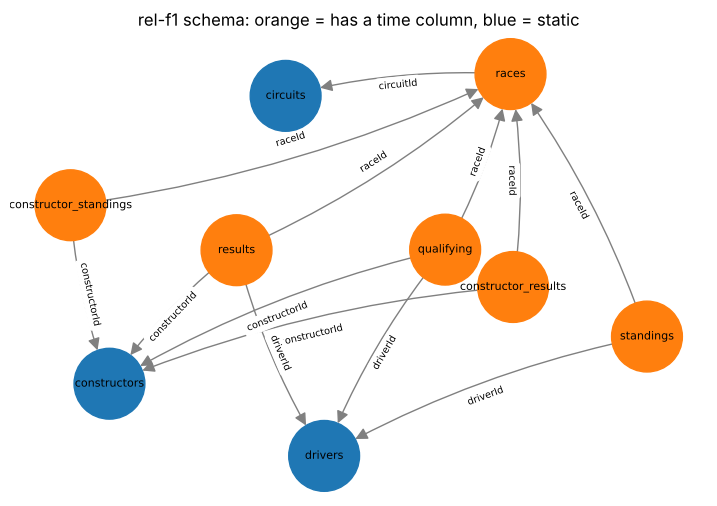

9 tables, 13 foreign keys


In [4]:
G = nx.DiGraph()
for name, t in db.table_dict.items():
    G.add_node(name, timed=t.time_col is not None)
    for fkey, target in t.fkey_col_to_pkey_table.items():
        G.add_edge(name, target, label=fkey)

pos = nx.spring_layout(G, seed=3, k=1.6)
colors = ['tab:orange' if G.nodes[n]['timed'] else 'tab:blue' for n in G]
plt.figure(figsize=(9, 6))
nx.draw_networkx(G, pos, node_color=colors, node_size=2600, font_size=8,
                 arrowsize=18, edge_color='gray', connectionstyle='arc3,rad=0.08')
nx.draw_networkx_edge_labels(G, pos, nx.get_edge_attributes(G, 'label'), font_size=7)
plt.title('rel-f1 schema: orange = has a time column, blue = static')
plt.axis('off'); plt.show()
print(len(G.nodes), 'tables,', len(G.edges), 'foreign keys')

## Step 3: a task's training table

A task is a table of `(entity, timestamp, label)` rows. For `driver-top3`, the label
says whether the driver qualifies in the top 3 within the 30 days after the timestamp.

In [5]:
task = dataset.load_task('driver-top3')
print(task.task_type, '| entity table:', task.entity_table, '| label column:', task.target_col,
      '| window:', task.timedelta)
tables = {split: task.get_table(split) for split in ['train', 'val', 'test']}
display(tables['train'].df.head())

for split, t in tables.items():
    df = t.df
    labels = (f"positive rate {df[task.target_col].mean():.3f}" if task.target_col in df
              else 'labels hidden')
    print(f"{split:5s} {len(df):5d} rows | {df.date.nunique():3d} timestamps "
          f"{df.date.min().date()} → {df.date.max().date()} | {labels}")

TaskType.BINARY_CLASSIFICATION | entity table: drivers | label column: qualifying | window: 30 days 00:00:00


,date,driverId,qualifying
0,1994-02-28,21,0
1,1994-02-28,29,1
2,1994-02-28,43,0
3,1994-02-28,48,0
4,1994-02-28,49,0


train  1353 rows |  59 timestamps 1994-02-28 → 2004-10-03 | positive rate 0.171
val     588 rows |  27 timestamps 2005-03-02 → 2008-03-16 | positive rate 0.202
test    726 rows |  30 timestamps 2010-03-02 → 2013-03-16 | labels hidden


## Step 4: column types (stypes)

PyTorch Frame encodes each column by its semantic type. Primary and foreign keys are
dropped later, because the graph structure already carries them.

In [6]:
col_to_stype = get_stype_proposal(db)
for table in ['drivers', 'results']:
    print(table, {c: str(s) for c, s in col_to_stype[table].items()})

# This walkthrough skips text columns (Part 2 covers the GloVe text encoder):
col_to_stype = {t: {c: s for c, s in cols.items() if s != torch_frame.text_embedded}
                for t, cols in col_to_stype.items()}

drivers {'driverId': 'numerical', 'driverRef': 'text_embedded', 'code': 'text_embedded', 'forename': 'text_embedded', 'surname': 'text_embedded', 'dob': 'timestamp', 'nationality': 'text_embedded'}
results {'resultId': 'numerical', 'raceId': 'numerical', 'driverId': 'numerical', 'constructorId': 'numerical', 'number': 'numerical', 'grid': 'numerical', 'position': 'numerical', 'positionOrder': 'numerical', 'points': 'numerical', 'laps': 'numerical', 'milliseconds': 'numerical', 'fastestLap': 'numerical', 'rank': 'numerical', 'statusId': 'numerical', 'date': 'timestamp'}


## Step 5: the database as a PyG `HeteroData` graph

`make_pkey_fkey_graph` builds one node type per table, two edge types per foreign key
(`f2p_<fkey>` row→referenced row, and its reverse `rev_f2p_<fkey>`), a `TensorFrame`
of features per node type, and a `time` vector for timed tables.

In [7]:
data, col_stats = make_pkey_fkey_graph(
    db, col_to_stype_dict=col_to_stype, text_embedder_cfg=None,
    cache_dir=str(ROOT / 'data/materialized/rel-f1/none'))
print(data)

HeteroData(
  races={
    tf=TensorFrame([820, 4]),
    time=[820],
  },
  qualifying={
    tf=TensorFrame([4082, 3]),
    time=[4082],
  },
  constructor_standings={
    tf=TensorFrame([10170, 4]),
    time=[10170],
  },
  standings={
    tf=TensorFrame([28115, 4]),
    time=[28115],
  },
  constructors={ tf=TensorFrame([211, 1]) },
  drivers={ tf=TensorFrame([857, 1]) },
  constructor_results={
    tf=TensorFrame([9408, 2]),
    time=[9408],
  },
  circuits={ tf=TensorFrame([77, 3]) },
  results={
    tf=TensorFrame([20323, 11]),
    time=[20323],
  },
  (races, f2p_circuitId, circuits)={ edge_index=[2, 820] },
  (circuits, rev_f2p_circuitId, races)={ edge_index=[2, 820] },
  (qualifying, f2p_raceId, races)={ edge_index=[2, 4082] },
  (races, rev_f2p_raceId, qualifying)={ edge_index=[2, 4082] },
  (qualifying, f2p_driverId, drivers)={ edge_index=[2, 4082] },
  (drivers, rev_f2p_driverId, qualifying)={ edge_index=[2, 4082] },
  (qualifying, f2p_constructorId, constructors)={ edge_inde

In [8]:
print(len(data.node_types), 'node types,', len(data.edge_types), 'edge types\n')
for edge_type in data.edge_types[:4]:
    print(edge_type, tuple(data[edge_type].edge_index.shape))

# Every rev_ edge type is the transpose of its f2p_ edge type:
for src, rel, dst in data.edge_types:
    if rel.startswith('f2p_'):
        fwd = data[src, rel, dst].edge_index
        rev = data[dst, 'rev_' + rel, src].edge_index
        assert set(map(tuple, fwd.t().tolist())) == set(map(tuple, rev.flip(0).t().tolist()))
print('\nall rev_ edges are transposes ✓')

9 node types, 26 edge types

('races', 'f2p_circuitId', 'circuits') (2, 820)
('circuits', 'rev_f2p_circuitId', 'races') (2, 820)
('qualifying', 'f2p_raceId', 'races') (2, 4082)
('races', 'rev_f2p_raceId', 'qualifying') (2, 4082)



all rev_ edges are transposes ✓


In [9]:
tf = data['results'].tf
print('results TensorFrame:', tf.num_rows, 'rows')
for stype, cols in tf.col_names_dict.items():
    print(f'  {str(stype):12s} {cols}  → tensor {tuple(tf.feat_dict[stype].shape)}')
print('time (unix s) of first 3 results:', data['results'].time[:3].tolist(),
      '→', pd.to_datetime(data['results'].time[:3].numpy(), unit='s').date.tolist())
print('drivers has time?', 'time' in data['drivers'])

results TensorFrame: 20323 rows
  numerical    ['fastestLap', 'grid', 'laps', 'milliseconds', 'number', 'points', 'position', 'positionOrder', 'rank', 'statusId']  → tensor (20323, 10)
  timestamp    ['date']  → tensor (20323, 1, 7)
time (unix s) of first 3 results: [-619747200, -619747200, -619747200] → [datetime.date(1950, 5, 13), datetime.date(1950, 5, 13), datetime.date(1950, 5, 13)]
drivers has time? False


## Step 6: one driver followed through the graph

Michael Schumacher is driver 29. Hop 1 along `rev_f2p_driverId` gives his rows in
`results`; hop 2 along `f2p_raceId` gives the races of those results.

In [10]:
driver = 29
ei = data['drivers', 'rev_f2p_driverId', 'results'].edge_index
his_results = ei[1, ei[0] == driver]
print('hop 1: results rows of driver 29:', len(his_results))

res = db.table_dict['results'].df.loc[his_results.numpy(), ['raceId', 'positionOrder', 'points', 'date']]
display(res.sort_values('date').head())

ei2 = data['results', 'f2p_raceId', 'races'].edge_index
mask = torch.isin(ei2[0], his_results)
his_races = ei2[1, mask].unique()
print('hop 2: distinct races reached:', len(his_races),
      '| first / last:', races.loc[his_races.numpy(), 'date'].min().date(),
      races.loc[his_races.numpy(), 'date'].max().date())

hop 1: results rows of driver 29: 250


,raceId,positionOrder,points,date
13312,510,26,0.0,1991-08-25
13363,511,5,2.0,1991-09-08
13404,512,6,1.0,1991-09-22
13445,513,6,1.0,1991-09-29
13464,514,14,0.0,1991-10-20


hop 2: distinct races reached: 250 | first / last: 1991-08-25 2006-10-22


## Step 7: seeds

Each training row `(driverId, t, label)` becomes a **seed**: a driver node plus the
time `t` at which we predict. The same driver appears many times with different `t`.

In [11]:
train_input = get_node_train_table_input(table=tables['train'], task=task)
node_type, nodes = train_input.nodes
print('seed node type:', node_type, '| #seeds:', len(nodes))
print('first 5 seeds (driverId, time, label):')
for n, t, y in zip(nodes[:5], train_input.time[:5], train_input.target[:5]):
    print(f'  driver {int(n):3d}  t={pd.to_datetime(int(t), unit="s").date()}  y={int(y)}')
print('driver 29 appears', int((nodes == driver).sum()), 'times as a seed')

seed node type: drivers | #seeds: 1353
first 5 seeds (driverId, time, label):
  driver  21  t=1994-02-28  y=0
  driver  29  t=1994-02-28  y=1
  driver  43  t=1994-02-28  y=0
  driver  48  t=1994-02-28  y=0
  driver  49  t=1994-02-28  y=0
driver 29 appears 58 times as a seed


## Step 8: one mini-batch

`NeighborLoader` samples, for every seed, a 2-hop neighbourhood using only rows with
`time ≤ seed time`. We use tiny settings here (4 seeds, fan-out `[4, 2]` per edge type)
so the output is readable; the baseline uses 512 seeds and `[128, 64]` (Step 11).

In [12]:
loader = NeighborLoader(
    data, num_neighbors=[4, 2], time_attr='time',
    input_nodes=train_input.nodes, input_time=train_input.time,
    transform=train_input.transform, batch_size=4, temporal_strategy='uniform',
    shuffle=True)
batch = next(iter(loader))
print(batch)

HeteroData(
  races={
    tf=TensorFrame([33, 4]),
    time=[33],
    n_id=[33],
    batch=[33],
    num_sampled_nodes=[3],
  },
  qualifying={
    tf=TensorFrame([12, 3]),
    time=[12],
    n_id=[12],
    batch=[12],
    num_sampled_nodes=[3],
  },
  constructor_standings={
    tf=TensorFrame([0, 4]),
    time=[0],
    n_id=[0],
    batch=[0],
    num_sampled_nodes=[3],
  },
  standings={
    tf=TensorFrame([12, 4]),
    time=[12],
    n_id=[12],
    batch=[12],
    num_sampled_nodes=[3],
  },
  constructors={
    tf=TensorFrame([7, 1]),
    n_id=[7],
    batch=[7],
    num_sampled_nodes=[3],
  },
  drivers={
    tf=TensorFrame([4, 1]),
    n_id=[4],
    batch=[4],
    num_sampled_nodes=[3],
    input_id=[4],
    seed_time=[4],
    batch_size=4,
    y=[4],
  },
  constructor_results={
    tf=TensorFrame([0, 2]),
    time=[0],
    n_id=[0],
    batch=[0],
    num_sampled_nodes=[3],
  },
  circuits={
    tf=TensorFrame([0, 3]),
    n_id=[0],
    batch=[0],
    num_sampled_nodes=[3],
  

In [13]:
d = batch['drivers']
print('first 4 drivers nodes are the seeds:')
print('  n_id (global driverId) :', d.n_id[:4].tolist())
print('  input_id (train row)   :', d.input_id.tolist())
print('  seed_time              :', pd.to_datetime(d.seed_time.numpy(), unit='s').date.tolist())
print('  y (label)              :', d.y.tolist())
# batch[T].batch says which seed each sampled node belongs to: count nodes per (type, seed)
counts = pd.DataFrame({nt: torch.bincount(batch[nt].batch, minlength=4).tolist()
                       for nt in batch.node_types},
                      index=[f'seed {i} (driver {int(n)})' for i, n in enumerate(d.n_id[:4])])
print('\nsampled nodes per seed (columns = node types):')
counts

first 4 drivers nodes are the seeds:
  n_id (global driverId) : [17, 112, 30, 68]
  input_id (train row)   : [1110, 164, 1179, 413]
  seed_time              : [datetime.date(2003, 8, 10), datetime.date(1994, 7, 28), datetime.date(2004, 2, 6), datetime.date(1995, 8, 22)]
  y (label)              : [0.0, 0.0, 1.0, 0.0]

sampled nodes per seed (columns = node types):


,races,qualifying,constructor_standings,standings,constructors,drivers,constructor_results,circuits,results
seed 0 (driver 17),12,4,0,4,4,1,0,0,4
seed 1 (driver 112),0,0,0,0,0,1,0,0,0
seed 2 (driver 30),11,4,0,4,1,1,0,0,4
seed 3 (driver 68),10,4,0,4,2,1,0,0,4


### What the counts show

- **A seed can have an empty subgraph.** If the driver has no rows before the seed
  time (e.g. a debut race inside the label window), the model sees only the driver's
  own features. The next cell counts how often that happens.
- **Three tables never appear:** `constructor_standings`, `constructor_results` and
  `circuits` are **3 hops** from `drivers` (e.g. drivers → results → races → circuits),
  but the baseline samples (and message-passes over) only 2. With the schema graph as
  given, a 2-layer GNN cannot use them at all. This is one concrete form of what the
  paper calls *semantic fragmentation*.

In [14]:
first_result = db.table_dict['results'].df.groupby('driverId').date.min()
for split in ['train', 'val']:
    df = tables[split].df
    cold = (df.driverId.map(first_result) >= df.date)  # NaN (never raced) counts as False
    print(f'{split:5s}: {int(cold.sum()):3d} of {len(df)} seeds have no result before their '
          f'seed time | positive rate among them {df[cold][task.target_col].mean():.3f} '
          f'vs {df[task.target_col].mean():.3f} overall')

train:  55 of 1353 seeds have no result before their seed time | positive rate among them 0.018 vs 0.171 overall
val  :  22 of 588 seeds have no result before their seed time | positive rate among them 0.045 vs 0.202 overall


## Step 9: check that no future rows are sampled

For every sampled node of a timed table, its time must be ≤ the seed time of the
subgraph it belongs to (`batch[T].batch` says which seed).

In [15]:
seed_time = batch['drivers'].seed_time
for nt in batch.node_types:
    if 'time' in batch[nt]:
        if batch[nt].num_nodes == 0:
            print(f'{nt:22s} (no rows sampled for these 4 seeds)')
            continue
        gap_days = (seed_time[batch[nt].batch] - batch[nt].time) / 86400
        assert (gap_days >= 0).all(), nt
        print(f'{nt:22s} {batch[nt].num_nodes:3d} rows | min gap {gap_days.min():8.1f} days '
              f'| max gap {gap_days.max():9.1f} days')
print('no future rows ✓')

races                   33 rows | min gap      9.0 days | max gap    1246.0 days
qualifying              12 rows | min gap     38.0 days | max gap    1247.0 days
constructor_standings  (no rows sampled for these 4 seeds)
standings               12 rows | min gap     23.0 days | max gap    1162.0 days
constructor_results    (no rows sampled for these 4 seeds)
results                 12 rows | min gap      9.0 days | max gap    1134.0 days
no future rows ✓


## Step 10: one seed's subgraph

`disjoint=True` (forced by temporal sampling) gives every seed its own copy of every
sampled node, so the subgraph of seed 0 is exactly the nodes with `batch == 0`.

Arrows point in the direction messages flow (source → target). The seed and its `results` / `qualifying` / `standings` rows are linked in both directions (`f2p_driverId` and `rev_f2p_driverId`); hop-2 nodes (`races`, `constructors`) only send messages towards hop-1 rows, so after 2 layers their information reaches the seed.

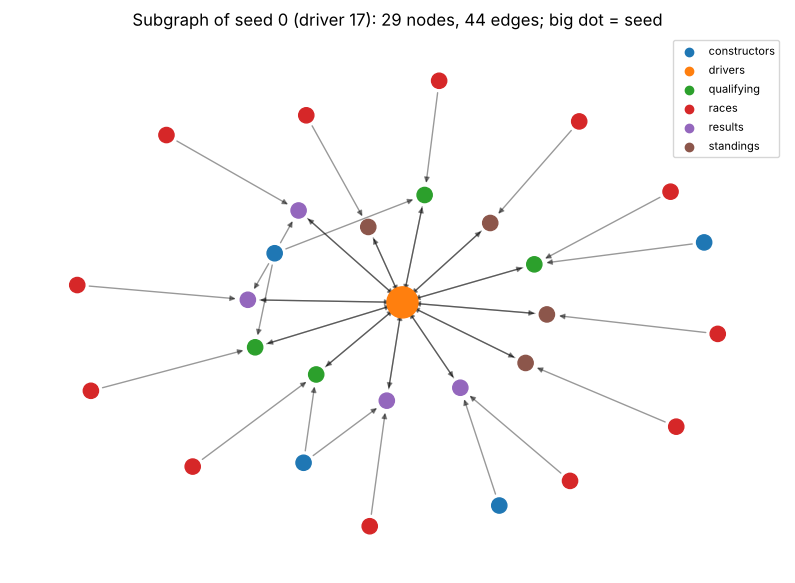

In [16]:
seed = 0
H = nx.DiGraph()
for nt in batch.node_types:
    for i in (batch[nt].batch == seed).nonzero().view(-1).tolist():
        H.add_node((nt, i), node_type=nt)
for (src, rel, dst), ei in batch.edge_index_dict.items():
    for s, t in ei.t().tolist():
        if (src, s) in H and (dst, t) in H:
            H.add_edge((src, s), (dst, t))

types = sorted({H.nodes[n]['node_type'] for n in H})
cmap = dict(zip(types, plt.cm.tab10.colors))
plt.figure(figsize=(10, 7))
pos = nx.spring_layout(H, seed=1)
nx.draw_networkx_nodes(H, pos, node_color=[cmap[H.nodes[n]['node_type']] for n in H],
                       node_size=[500 if n == ('drivers', seed) else 120 for n in H])
nx.draw_networkx_edges(H, pos, alpha=0.4, arrowsize=8)
for t in types:
    plt.scatter([], [], color=cmap[t], label=t)
plt.legend(fontsize=8); plt.axis('off')
plt.title(f'Subgraph of seed 0 (driver {int(batch["drivers"].n_id[seed])}): '
          f'{H.number_of_nodes()} nodes, {H.number_of_edges()} edges; big dot = seed')
plt.show()

## Step 11: a mini-batch at the real settings

The baseline uses 512 seeds and fan-out `[128, 64]` per edge type.

In [17]:
big = NeighborLoader(
    data, num_neighbors=[128, 64], time_attr='time',
    input_nodes=train_input.nodes, input_time=train_input.time,
    transform=train_input.transform, batch_size=512, temporal_strategy='uniform',
    shuffle=True)
b = next(iter(big))
rows = [(nt, b[nt].num_nodes) for nt in b.node_types]
print(pd.DataFrame(rows, columns=['node type', 'sampled nodes']).to_string(index=False))
print('total nodes:', sum(n for _, n in rows),
      '| total edges:', sum(e.size(1) for e in b.edge_index_dict.values()),
      '| batches per epoch:', len(big))

            node type  sampled nodes
                races          33252
           qualifying          12492
constructor_standings              0
            standings          29376
         constructors           1249
              drivers            512
  constructor_results              0
             circuits              0
              results          29533
total nodes: 106414 | total edges: 256189 | batches per epoch: 3


## Recap

- A database becomes a heterogeneous graph mechanically: tables → node types, foreign
  keys → edge types (plus reverses). This *schema graph* is what the paper improves on.
- A training example is a `(driver, time)` seed; its input is a time-respecting 2-hop
  subgraph, sampled fresh every time.
- Next: **Walkthrough 2**, where the model turns this batch into `h⁽⁰⁾` (encoders), runs
  message passing, computes the loss and takes one optimiser step.